In [2]:
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import seaborn as sns
import model
import json, csv
import mvpy
import plots

from copy import deepcopy

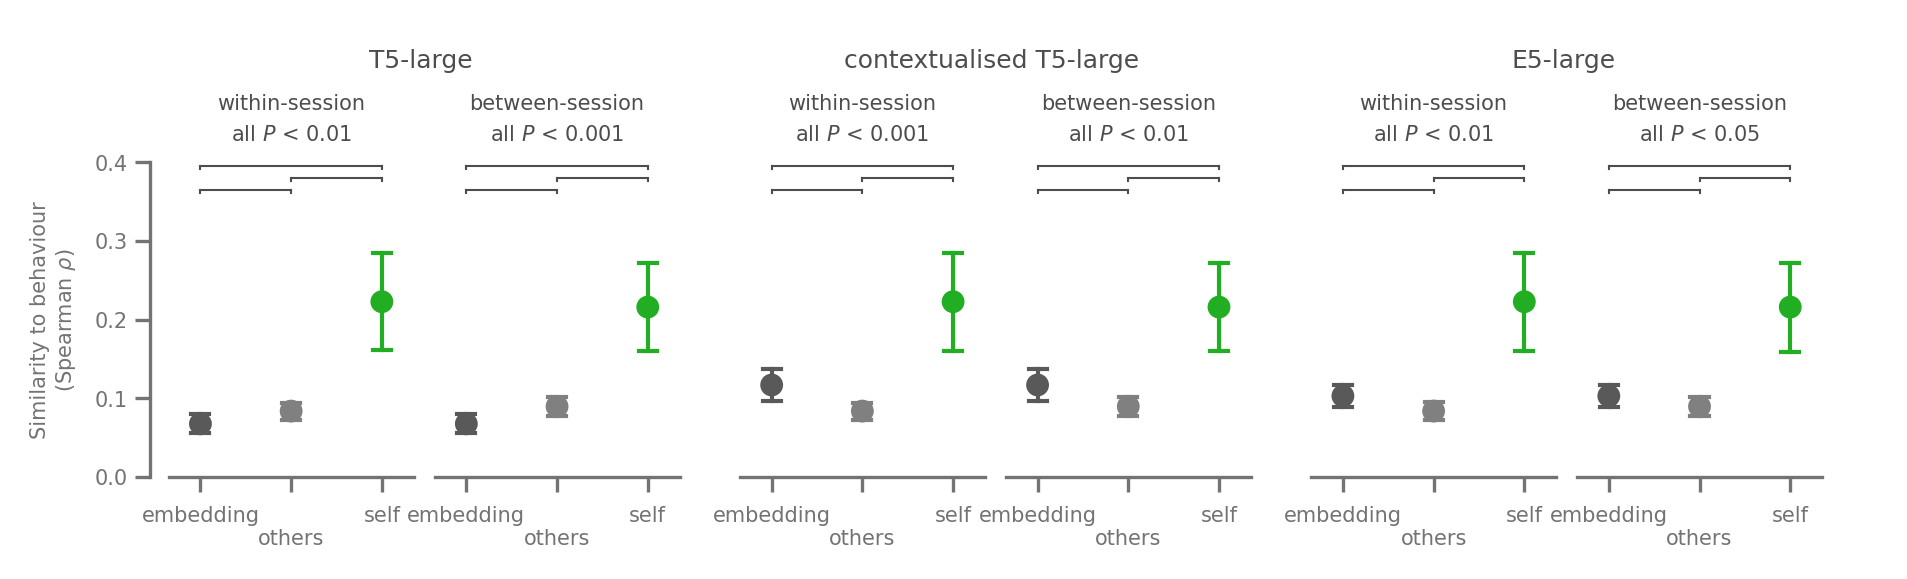

In [40]:
hypothesis_test = 'sign'
hypothesis_alternative = 'two-sided'
hypothesis_method = 'holm'
hypothesis_se = 'within'

run = 0
exp = 1

mods = [
    't5-large',
    't5-large-context',
    'e5-large'
]

mods_label = [
    fr'T5-large',
    fr'contextualised T5-large',
    fr'E5-large',
]

# initialise plot
fig, ax = plt.subplots(figsize = (6.4, 2.0), dpi = 300)

#cv4 = ax.inset_axes([0.0, 0.0, 0.30, 1.0])
cvs = []
offset_ax = 0.075

for mod_i, mod in enumerate(mods):
    share = 1 / len(mods)
    cv4 =  ax.inset_axes([share * mod_i - offset_ax, 0.0, share + offset_ax, 1.0])
    cv4.axis('off')

    cols = np.array([
        plots.colours.HL_EMBEDDING,
        plots.colours.HL_OTHERS,
        plots.colours.HL_SELF
    ])

    # within-session boards (5 folds)
    cv4_a1 = cv4.inset_axes([0.19, 0.075, 0.35, 0.65])

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macrossreliability_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    R_base = 0.5 * R['rho_emb'].squeeze().cpu().numpy().diagonal() + 0.5 * R['rho_bme'].squeeze().cpu().numpy().diagonal()

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-mareliability_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    #R_base = R['rho_emb'].squeeze().cpu().numpy().diagonal()
    R_indiv = R['rho'].cpu().numpy().diagonal()
    R_group = R['rho'].cpu().numpy()
    R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

    R_a = np.array([R_base, R_group, R_indiv])
    R_d = R_a.copy()
    X_jitter = np.random.uniform(-0.15, 0.15, size = (R_base.shape[0],))

    offset = 0
    ci_off = 0.1

    for i, R_i in enumerate(R_d):
        mu = R_i.mean()
        se = model.stats.bootstrap_se(R_i)

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

        cv4_a1.scatter([i], [mu], marker = 'o', edgecolor = 'None', facecolor = cols[i], s = 30, clip_on = False)
        cv4_a1.plot([i, i], [mu - 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
        cv4_a1.plot([i-ci_off, i+ci_off], [mu - 1.96 * se, mu - 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
        cv4_a1.plot([i-ci_off, i+ci_off], [mu + 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)

    design = [(1, 0), (2, 1), (2, 0)]
    group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig1/{mod}_wthn_group.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig1/{mod}_wthn_pairs.csv')

    # significance
    count = 0.0
    gain = 0.015
    min_p = 0.0
    offset = 0.365

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            if p_i > min_p:
                min_p = p_i

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = offset + count * gain
            cv4_a1.plot([ii, jj], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv4_a1.plot([ii, ii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv4_a1.plot([jj, jj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            count += 1

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    cv4_a1.annotate(f'all {rep_p}', xy = (0, 0), xytext = (1.0, 0.435), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

    # between-session boards (5 folds)
    cv4_a2 = cv4.inset_axes([0.57, 0.075, 0.35, 0.65])

    R = torch.load(f'../data/ds-exp{exp}/derivatives/run-00{run}/tasks/task-macrossreliability_bse0-{mod}_mod-delta.pt', map_location=torch.device('cpu'))
    R_base = 0.5 * R['rho_emb'].squeeze().cpu().numpy().diagonal() + 0.5 * R['rho_bme'].squeeze().cpu().numpy().diagonal()
    R_indiv = R['rho'].cpu().numpy().diagonal()
    R_group = R['rho'].cpu().numpy()
    R_group = R_group[np.eye(R_group.shape[0], dtype = bool) == False].reshape((R_group.shape[0], R_group.shape[0] - 1)).mean(-1)

    R_a = np.array([R_base, R_group, R_indiv])
    R_d = R_a.copy()

    offset = 0
    ci_off = 0.1

    for i, R_i in enumerate(R_d):
        mu = R_i.mean()
        se = model.stats.bootstrap_se(R_i)

        if offset < (mu + 1.96 * se):
            offset = mu + 1.96 * se

        cv4_a2.scatter([i], [mu], marker = 'o', edgecolor = 'None', facecolor = cols[i], s = 30, clip_on = False)
        cv4_a2.plot([i, i], [mu - 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
        cv4_a2.plot([i-ci_off, i+ci_off], [mu - 1.96 * se, mu - 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)
        cv4_a2.plot([i-ci_off, i+ci_off], [mu + 1.96 * se, mu + 1.96 * se], color = cols[i], lw = 1.0, clip_on = False)

    design = [(1, 0), (2, 1), (2, 0)]
    group = model.stats.sample_tests(R_a, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)
    pairwise = model.stats.pairwise_tests(R_a, design, test = hypothesis_test, alternative = hypothesis_alternative, method = hypothesis_method, se = hypothesis_se)

    model.stats.save_results(group, f'./deliverable/csv/suppfig1/{mod}_btwn_groups.csv')
    model.stats.save_results(pairwise, f'./deliverable/csv/suppfig1/{mod}_btwn_pairs.csv')

    # significance
    count = 0.0
    offset = 0.365
    min_p = 0.0

    for i, (ii, jj) in enumerate(design):
        p_i = pairwise[i]['p_cor']
        if p_i < .05:
            if p_i > min_p:
                min_p = p_i

            sig = 'n.s.' if p_i > 0.05 else '*' if p_i > 1e-2 else '**' if p_i > 1e-3 else '***'
            yy = offset + count * gain
            cv4_a2.plot([ii, jj], [yy, yy], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv4_a2.plot([ii, ii], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            cv4_a2.plot([jj, jj], [yy, yy - gain / 4], color = plots.colours.H2, linewidth = 0.5, clip_on = False)
            count += 1

    rep_p = 'n.s.' if min_p > .05 else fr'$P$ < 0.05' if min_p > 1e-2 else '$P$ < 0.01' if min_p > 1e-3 else '$P$ < 0.001'
    cv4_a2.annotate(f'all {rep_p}', xy = (0, 0), xytext = (1.0, 0.435), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2)

    for i, ax_i in enumerate([cv4_a1, cv4_a2]):
        label = 'within-session' if i == 0 else 'between-session'
        ax_i.annotate(label, xy = (0, 0), xytext = (1.0, 0.475), ha = 'center', va = 'center', fontsize = 5, color = plots.colours.H2, annotation_clip = False)

        xticks = ['embedding', '\nothers', 'self']# if i == 0 else []
        ylabel = 'Similarity to behaviour\n' + fr'(Spearman $\rho$)' if i == 0 else ''
        yticks = [0.0, 0.1, 0.2, 0.3, 0.4] if i == 0 else []
        yvis = True if i == 0 else False
        ypos = -0.075

        ax_i.set_xlim([-0.35, 2.35])
        ax_i.set_xticks([0, 1, 2])
        ax_i.set_xticklabels(xticks, fontsize = 5)
        ax_i.set_ylim([0.0, 0.4])
        ax_i.set_yticks(yticks)
        ax_i.set_ylabel(ylabel, fontsize = 5)
        ax_i.tick_params(axis = 'y', labelsize = 5, pad = 2)

        ax_i.yaxis.label.set_color(plots.colours.H3)
        ax_i.tick_params(axis = 'x', colors = plots.colours.H3)
        ax_i.tick_params(axis = 'y', colors = plots.colours.H3)
        ax_i.spines['bottom'].set_color(plots.colours.H3)
        ax_i.spines['left'].set_color(plots.colours.H3)

        sns.despine(ax = ax_i)
        ax_i.spines['left'].set_visible(yvis)
        ax_i.spines['left'].set_position(('axes', ypos))
        
        if mod_i > 0:
            ax_i.set_yticklabels([])
            ax_i.set_ylabel('')
            ax_i.spines['left'].set_visible(False)
            ax_i.tick_params(axis = 'y', which = 'both', length = 0)
    
    cv4.annotate(
        fr'{mods_label[mod_i]}',
        xy = (0.0, 0.0),
        xytext = (0.55, 0.935),
        ha = 'center',
        va = 'center',
        fontsize = 6,
        color = plots.colours.H2,
    )
    
    cvs.append(cv4)
    cvs.append(cv4_a1)
    cvs.append(cv4_a2)

'''
cosmetics
'''

fig.tight_layout()

ax.axis('off')

fig.savefig('./deliverable/png/suppfig1.png', dpi = 900)
fig.savefig('./deliverable/pdf/suppfig1.pdf', dpi = 900, format = 'pdf')
fig.savefig('./deliverable/svg/suppfig1.svg', dpi = 900, format = 'svg')